## Synthoseis Quick Start Notebook

Synthoseis is an open source, Python-based tool used for generating pseudo-random seismic data. The goal of Synthoseis is to generate realistic seismic data for deep learning training. This notebook will serve as a guide to getting your first Synthoseis model up and running. Future notebooks will discuss seismic outputs, visualizations, and building a custom rock properties model.

### Environment Build

To install the necessary packages, use the `environment.yml` file to create a virtual or conda environment. Please note that the most recent version of Synthoseis has been refactored to work with Python 3.10.

### Setup

In [2]:
import sys
import os

# Add project root to Python path for imports
notebook_dir = os.path.dirname(os.path.abspath('__file__'))
project_root = os.path.dirname(notebook_dir)
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Get cross-platform temp directory for output
import tempfile
TEMP_WORK_DIR = tempfile.gettempdir()

### Imports

Within the main directory of the repo is a script called `main.py`. This is the primary script to run the program. Import `main.py`, along with visualization tools to view the results.

In [ ]:
import sys
import os
sys.path.append('../')


import main as mn 
import numpy as np
import json
import pprint as pp
import matplotlib.pyplot as plt

: 

### Building your first model

The config json file is the method for defining some of the key aspects of your seismic survey including survey size, seismic bandwith, column height range, number of faults, sand thickness ranges, and the presence of geobodies like salt and channels. Please note that setting `include_channels: True` will signifcantly increase compute time and memory consumption. Below is an example config file that can be found in `./config/example.json`.

In [4]:
config_path = os.path.join(project_root, 'config', 'example.json')
rock_model = json.load(open(config_path, 'r'))

# Update paths for cross-platform compatibility
rock_model['project_folder'] = os.path.join(TEMP_WORK_DIR, 'synthoseis_example')
rock_model['work_folder'] = TEMP_WORK_DIR

pp.pprint(rock_model)

{'bandwidth_high': [20.0, 35.0],
 'bandwidth_low': [3.0, 6.0],
 'bandwidth_ord': 4,
 'basin_floor_fans': False,
 'broadband_qc_volume': False,
 'closure_types': ['simple', 'faulted', 'onlap'],
 'cube_shape': [300, 300, 1250],
 'digi': 4,
 'dip_factor_max': 2,
 'extra_qc_plots': True,
 'incident_angles': [7, 15, 24],
 'include_channels': False,
 'include_salt': True,
 'infill_factor': 10,
 'initial_layer_stdev': [7.0, 25.0],
 'max_column_height': [150.0, 150.0],
 'max_number_faults': 6,
 'min_closure_voxels_faulted': 2500,
 'min_closure_voxels_onlap': 500,
 'min_closure_voxels_simple': 500,
 'min_number_faults': 1,
 'model_qc_volumes': True,
 'multiprocess_bp': True,
 'pad_samples': 10,
 'partial_voxels': True,
 'project': 'example',
 'project_folder': 'C:\\Users\\Ed\\AppData\\Local\\Temp\\synthoseis_example',
 'sand_layer_fraction': {'max': 0.25, 'min': 0.05},
 'sand_layer_thickness': 2,
 'seabed_min_depth': [20, 50],
 'signal_to_noise_ratio_db': [7.5, 12.5, 17.5],
 'thickness_max': 12

### Running the model

Once you've defined the parameters of your seismic data, call the `build_model()` function in `main.py`. This will take the config `.json` file as an input, as well as a `run_id` defined by the user. Users also have the option to use `test_mode`. Test mode can take an integer as an input and returns a smaller seismic volume than defined in the config file. This is great for testing prior to running the full size model.

In [ ]:
mn.build_model(user_json=config_path, run_id=1, test_mode=50)

------------------------------------
Testing Mode
Output Folder: /tmp\synthoseis_example_test_mode_
Cube_Shape: (50, 50, 1250)
------------------------------------
No coherent noise will be inserted
Salt will be inserted. noise_stretch_factor = 1.26

Model folder: /tmp\synthoseis_example_test_mode_\seismic__2026.15808583_1
Creating directory: /tmp\synthoseis_example_test_mode_
Creating directory: /tmp\synthoseis_example_test_mode_\seismic__2026.15808583_1
Creating directory: d:\tmp\temp_folder__2026.15808583_1_1__2026.15808583
Could not chmod /tmp\synthoseis_example_test_mode_\seismic__2026.15808583_1. Continuing...


FileNotFoundError: [Errno 2] No such file or directory: '/tmp\\synthoseis_example_test_mode_\\seismic__2026.15808583_1\\seismicCube_2026.15808583.key'

: 

Let's check to see if the test mode seismic data successfully wrote to a temp location. If the data looks correct, turn off test mode and run the full model. A full model of size `(300,300,1250)` will take 30-60 minutes to complete.

In [ ]:
seismic = np.load('/tmp/synthoseis_example_test_mode_/seismic__2024.06761594_1/seismicCubes_RFC_fullstack_2024.06761594.npy')
print(seismic.shape)

(50, 50, 1259)


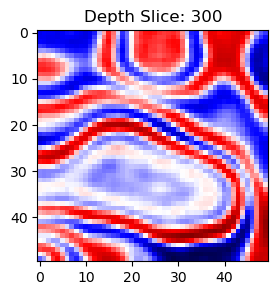

In [14]:
plt.figure(figsize=(3,3))
plt.title('Depth Slice: 300')
plt.imshow(seismic[...,300], cmap=plt.cm.seismic)
plt.show()